In [40]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import ttest_ind

df = pd.read_csv("../grunddata/health_study_dataset.csv")

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [42]:
df.isna().sum()

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

Här har jag kontrolerat om det finns nan värden i någon av kategorierna. Det finns det ej. Data settet är komplett.

In [43]:
disease_yes = df[df["disease"] == 1]
disease_no = df[df["disease"] == 0]

df["disease"].value_counts()

disease
0    753
1     47
Name: count, dtype: int64

In [44]:
#Nu vill jag undersöka vilka kategorier som har sjukdommar för en första översikt

pd.crosstab(df["age"], df["disease"])


disease,0,1
age,,
18,10,1
19,3,0
20,3,0
21,4,0
22,2,0
...,...,...
84,2,0
86,2,0
88,2,0


In [45]:
pd.crosstab(df["sex"], df["disease"])


disease,0,1
sex,,
F,385,18
M,368,29


Fler män än kvinnor har sjukdom

In [46]:
pd.crosstab(df["weight"], df["disease"])

disease,0,1
weight,,
33.7,1,0
33.9,1,0
35.5,1,0
38.1,1,0
41.6,1,0
...,...,...
106.6,1,0
106.9,1,0
107.3,2,0


In [47]:
pd.crosstab(df["systolic_bp"], df["disease"])

disease,0,1
systolic_bp,,
106.8,1,0
116.3,1,0
117.1,1,0
117.8,1,0
118.5,1,0
...,...,...
183.3,1,0
183.8,1,0
184.1,1,0


In [48]:
pd.crosstab(df["cholesterol"], df["disease"])

disease,0,1
cholesterol,,
2.50,2,0
2.54,1,0
2.64,1,0
2.78,2,0
2.81,1,0
...,...,...
7.23,1,0
7.36,1,0
7.41,1,0


In [49]:
pd.crosstab(df["smoker"], df["disease"])

disease,0,1
smoker,,
No,559,28
Yes,194,19


In [50]:
pd.crosstab(df["height"], df["disease"])


disease,0,1
height,,
144.4,1,0
146.5,1,0
146.8,1,0
147.1,1,0
147.9,1,0
...,...,...
195.5,1,0
195.9,1,0
196.1,1,1


Här ser vi att jag stöter på problem i visning av antalet sjukdomar i varje kategori. Cholesterol, weight, age och systolic_bp har för många unika värden för att enkelt ge dem ja eller nej på samma sätt som smoker och sex ger. Därför behöver jag skapa grafer för dessa kategorier som är otydliga för att se någon koppling. 

Något som är intressant från ovan är att icke rökare är fler än rökare i denna undersökning vad gäller sjukdom.
Andelen män är fler än kvinnor som har sjukdom. 

In [51]:
#gruppera age, cholesterol, weight och systolic_bp

disease_yes.groupby(
    pd.cut(disease_yes["age"], bins=[15, 25, 30, 35, 40, 45, 50, 55, 60, 70, 80, 90, 100])
).size()

age
(15, 25]     1
(25, 30]     2
(30, 35]     2
(35, 40]     5
(40, 45]     6
(45, 50]     7
(50, 55]    11
(55, 60]     3
(60, 70]     6
(70, 80]     3
(80, 90]     1
dtype: int64

In [52]:
disease_yes.groupby(
    pd.cut(disease_yes["cholesterol"], bins=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
).size()

cholesterol
(2, 3]     1
(3, 4]     3
(4, 5]    21
(5, 6]    19
(6, 7]     3
dtype: int64

In [53]:
disease_yes.groupby(
    pd.cut(disease_yes["weight"], bins=[0, 20, 30, 40, 50,  60, 70, 75, 80, 90, 100, 110, 130])
).size()

weight
(50, 60]       6
(60, 70]       6
(70, 75]      11
(75, 80]      10
(80, 90]      10
(90, 100]      3
(100, 110]     1
dtype: int64

In [54]:
disease_yes.groupby(
    pd.cut(disease_yes["systolic_bp"], bins=[50, 80, 100, 105, 110, 115, 120, 130, 140, 150, 160, 180, 200, 210])
).size()

systolic_bp
(120, 130]     4
(130, 140]     5
(140, 150]    14
(150, 160]    14
(160, 180]     9
(180, 200]     1
dtype: int64

In [55]:
disease_yes.groupby(
    pd.cut(disease_yes["height"], bins=[130, 140, 150, 160, 170, 180, 190, 200, 210])
).size()

height
(150, 160]     4
(160, 170]    13
(170, 180]    17
(180, 190]    11
(190, 200]     2
dtype: int64

I denna sortering ser vi att de som är sjuka är mellan 50-55 år, väger mellan 70-80 kg, har ett cholestrolvärde mellan 4-5 och blodtryck mellan 140-160. Där har vi vår riskzon. Om patienten dessutom är man är det ytterligare en indikator på risk.

In [56]:
#boxplot för ja och nej sjuk. för varje kategori. median och extremvärden. 

df.groupby("disease")[["age", "weight", "systolic_bp", "cholesterol", "height"]].describe()

age                                                     weight  \
         count       mean        std   min   25%   50%   75%   max  count   
disease                                                                     
0        753.0  49.347942  14.547101  18.0  39.0  50.0  59.0  90.0  753.0   
1         47.0  50.680851  13.831449  18.0  42.0  51.0  56.5  90.0   47.0   

                    ... cholesterol       height                               \
              mean  ...         75%   max  count        mean       std    min   
disease             ...                                                         
0        73.285126  ...       5.480  7.88  753.0  171.767995  9.805052  144.4   
1        75.461702  ...       5.495  6.96   47.0  173.151064  9.804056  152.6   

                                      
            25%    50%    75%    max  
disease                               
0        164.70  171.3  178.9  200.4  
1        166.45  172.8  181.1  196.1  

[2 rows x 40 columns]

In [57]:
df[["age", "weight", "systolic_bp", "cholesterol", "height"]].agg(["mean", "median", "min", "max"])

,age,weight,systolic_bp,cholesterol,height
mean,49.42625,73.413,149.178625,4.92915,171.84925
median,50.00000,73.200,149.400000,4.97000,171.35000
min,18.00000,33.700,106.800000,2.50000,144.40000
max,90.00000,114.400,185.900000,7.88000,200.40000


Ovan ser vi andelar för varje kategori. Medelvärde, standardavvikelse, max, min, kvartiler och antal för varje kategori baserat på sjuk = ja (1) eller nej (0)

Eftersom det är lite svårt att avläsa detta så ska jag bygga grafik på samma data. 

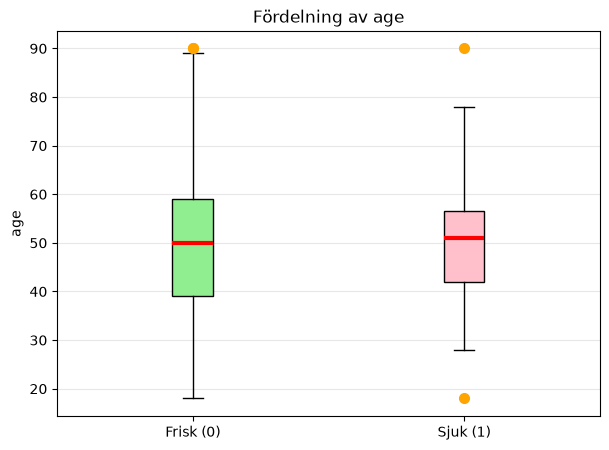

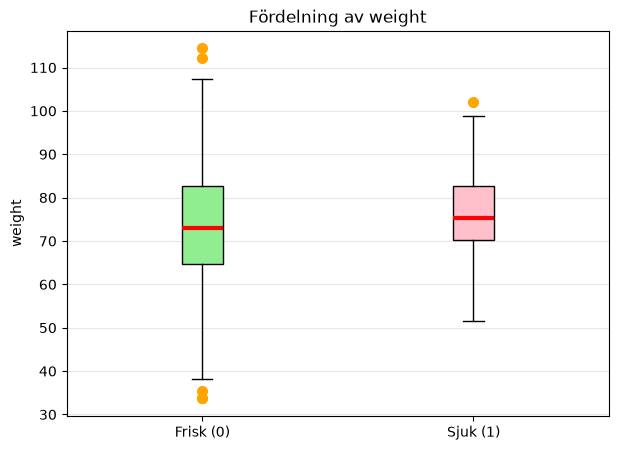

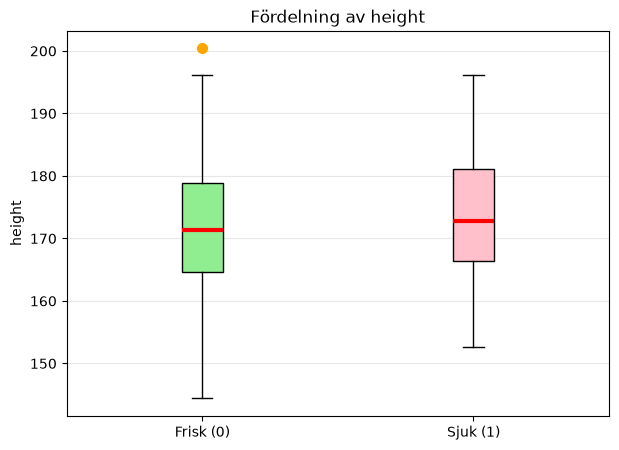

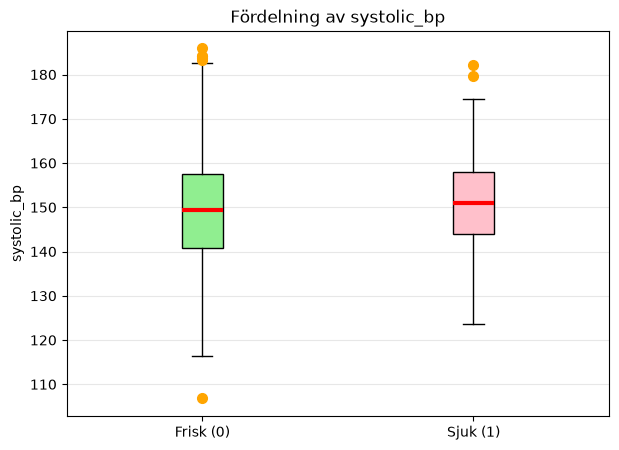

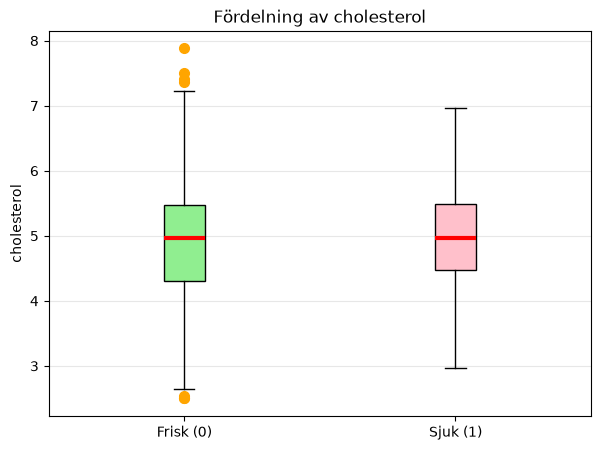

In [68]:
columns = ["age", "weight", "height", "systolic_bp", "cholesterol"]

for col in columns:
    healthy = disease_no[col]
    sick = disease_yes[col]

    plt.figure(figsize=(7,5))

    box = plt.boxplot(
        [healthy, sick],
        tick_labels=["Frisk (0)", "Sjuk (1)"],
        patch_artist=True,

        boxprops=dict(facecolor="lightblue", color="black"),
        medianprops=dict(color="red", linewidth=3),
        whiskerprops=dict(color="black"),
        flierprops=dict(
            marker="o",
            markerfacecolor="orange",
            markeredgecolor="orange",
            markersize=7
        )
    )

    colors = ["lightgreen", "pink"]

    for patch, color in zip(box["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_edgecolor("black")

    plt.title(f"Fördelning av {col}")
    plt.ylabel(col)
    plt.grid(axis="y", alpha=0.3)


    plt.show()

Dessa grafer visar att medianen är något högre på dem som är sjuka på alla parametrar förutom cholesterol. Det visar alltså att cholesterol värden ej är avgörande om individen blir sjuk eller ej. 

Den röda linjen i box plot graferna indikerar medianen.

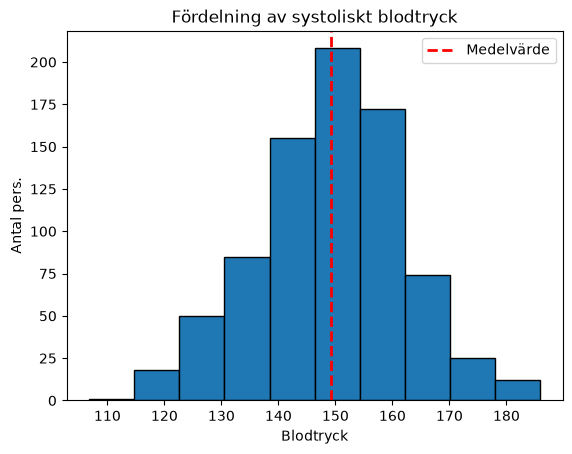

In [59]:
systolic_mean_bp = df["systolic_bp"].mean()
systolic_std_bp = df["systolic_bp"].std()

plt.hist(df["systolic_bp"], 
         bins=10,
         edgecolor="black")

plt.axvline(
    systolic_mean_bp,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Medelvärde"
)
plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Blodtryck")
plt.ylabel("Antal pers.")

plt.legend()
plt.show()

Här ser vi fördelningen av blodtrycket över hela populationen. Detta säger oss inte speciellt mycket om detta enbart skulle betyda sjukdom eller ej. Så vi undersöker vidare.

In [60]:
#normalapproximation för systolic bp

n = len(df) #stickprov ur population

standard_error = systolic_std_bp / np.sqrt(n)

lower_error = systolic_mean_bp - 1.96 * standard_error
upper_error = systolic_mean_bp + 1.96 * standard_error

print("Antal observationer: ", n)
print(f"95% konfidensintervall ur normalapproximation: {lower_error:.2f}, {upper_error:.2f}")

Antal observationer:  800
95% konfidensintervall ur normalapproximation: 148.29, 150.07


Både normalapproximationen och fördelningen av systoliskt blodtryck visar på samma eller liknande värden. Det innebär att med stor sannorlikhet att den normala systoliska blodtrycket ligger mellan 148 och 150.

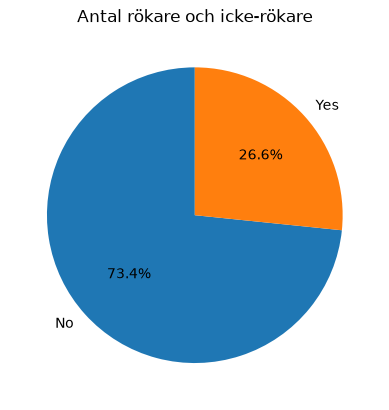

In [61]:
df["smoker"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90)
plt.title("Antal rökare och icke-rökare")
plt.show()

In [62]:
smoker_bp = df[df["smoker"] == "Yes"]["systolic_bp"]
non_smoker_bp = df[df["smoker"] == "No"]["systolic_bp"]
mean_bp_diff = smoker_bp.mean() - non_smoker_bp.mean()

print("Skillnad i medelvärde av blodtryck mellan rökare och icke rökare:", mean_bp_diff)

Skillnad i medelvärde av blodtryck mellan rökare och icke rökare: 0.47190136846063524


In [63]:
#Börja med konfidensintervall med bootstrap för skillnad mellan rökare och icke rökare. med random seed

np.random.seed(350)

bootstrap_diff_smoke = []

for _ in range(1000):
    smoker_sample = smoker_bp.sample(frac=1, replace=True)
    nosmoker_sample = non_smoker_bp.sample(frac=1, replace=True)

    diff = smoker_sample.mean() - nosmoker_sample.mean()

    bootstrap_diff_smoke.append(diff)

lower, upper = np.percentile(bootstrap_diff_smoke, [2.5, 97.5])

print(f"95% konfidensintervall, rökare och icke rökare: [{lower:.2f}, {upper:.2f}]")

95% konfidensintervall, rökare och icke rökare: [-1.54, 2.40]


Konfidensintervallen visar skillnaden mellan rökare och ickerökares systolik blodtryck i 95% av fallen. Värdet blev -1.54, 2.40 mellan dessa värden finns värde 0. Vilket innebär att det inte går att säkerställa att rökare har högre blodtryck än icke-rökare.

## BMI i påverkan om sjuk eller frisk

In [64]:
df["bmi"] = df["weight"] / (df["height"] / 100) ** 2
mean_bmi = df.groupby("disease")["bmi"].mean()
healthy_bmi_mean = mean_bmi.loc[0]
sick_bmi_mean = mean_bmi.loc[1]

print(f"Genomsnittlig BMI för friska: {healthy_bmi_mean:.2f}")
print(f"Genomsnittlig BMI för sjuka: {sick_bmi_mean:.2f}")

Genomsnittlig BMI för friska: 24.91
Genomsnittlig BMI för sjuka: 25.29


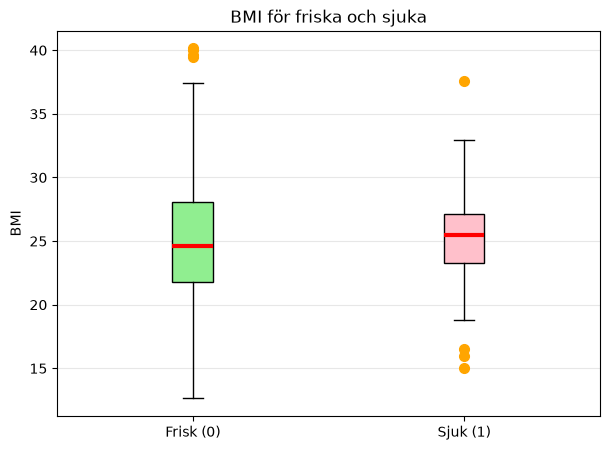

In [65]:
healthy_bmi = df[df["disease"] == 0]["bmi"]
sick_bmi = df[df["disease"] == 1]["bmi"]

plt.figure(figsize=(7,5))

box = plt.boxplot(
    [healthy_bmi, sick_bmi],
    tick_labels=["Frisk (0)", "Sjuk (1)"],
    patch_artist=True,

    boxprops=dict(facecolor="lightblue", color="black"),
    medianprops=dict(color="red", linewidth=3),
    whiskerprops=dict(color="black"),
    flierprops=dict(
        marker="o",
        markerfacecolor="orange",
        markeredgecolor="orange",
        markersize=7
    )
)

colors = ["lightgreen", "pink"]

for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor("black")

plt.title("BMI för friska och sjuka")
plt.ylabel("BMI")
plt.grid(axis="y", alpha=0.3)

plt.show()

BMI verkar ha påverkan på vilka som blir sjuka. Däremot finns det extremvärden på låg BMI, men det kanske beror på själva sjukdomen, det kan vi inte veta. Det vi ser är att BMI värdet är generellt högre när man är sjuk gentemot frisk. 

## Sammanfattning


Vi har 800 observationer i denna undersökning. 753 st är friska, 47 är sjuka.
Av dem 47 ser vi att dem har:

- Högre blodtryck
- Väger mer
- Har högre BMI
- Är äldre

Av dem som är sjuka är fler män. 

Vad vi även ser av denna undersökning är att rökning och cholestrolvärden inte verkar vara avgörande för att bli sjuk. 

Men riskområdet ligger: 
- mellan 50-55 år
- väger mellan 70-80 kg 
- har ett cholestrolvärde mellan 4-5 
- blodtryck mellan 140-160

Ytterligare risk är hög BMI och Man. 